# EDA: IV Drop Detection Dataset

**Project:** IV Drip Monitoring  
**My Part:** Drop Detection & Drip Rate  
**Dataset:** my fork of [Drip Infusion V2](https://universe.roboflow.com/andika-rizaldy/drip-infusion-v2) (Roboflow Universe, Andika Rizaldy, CC BY 4.0). In my fork I added boxes to 7 frames that showed a clear drop without a box, and I removed 3 frames where the drop was too small to box reliably. 1 more ambiguous frame is removed in Section 9.

The dataset uploader also coauthored *Drip Infusion Monitoring and Data Logging System Based on YOLOv5* (JITK, 2025).

## Key Findings
| # | What I found | My decision |
|---|---|---|
| 1 | The original dataset contains 9,480 images from 16 videos: 8 with black backgrounds and 8 with white backgrounds. The rates in the filenames are 20, 60, 70, and 80 DPM. | The dataset is suitable for training the detection model, but I will need complete external videos at 30 to 40 DPM to test the drip rate calculation. |
| 2 | There is only one class, tetesan (drop). Most boxes mark the drop hanging at the tip, while some images also contain a second box for the previous drop falling. | I kept valid two box images. The detection and counting logic must handle images with zero, one, or two drops. |
| 3 | Roboflow's original split has frames from 15 out of 16 videos in both training and validation. | I decided to split the data by video instead, using 11 videos for training, 3 for validation, and 2 for testing. Both background types will be included in every split. |
| 4 | Only 18 to 44% of the frame indices are available within each video's observed range. The frames appear in short consecutive groups with gaps in between. | I cannot rebuild the original videos from these images, so I will use complete external videos to evaluate the drip rate calculation. |
| 5 | The drop is very small. At imgsz = 640, its median size is approximately 13 × 16 pixels, and 10% of the boxes are 10 × 12 pixels or smaller. | I will pay close attention to recall, not just mAP50. If detection is not good enough, I will try cropping the drip chamber (ROI) or increasing the image size. |
| 6 | The drop appears at almost the same position across all videos. | I want to compare the default augmentation settings with stronger translate and scale augmentation to check whether the model is learning the drop's shape or mainly its position. |
| 7 | In some labeled sequences, the drop forms at the tip, hangs for a while, stretches, and is then replaced by a new small drop. | I will use this as a starting hypothesis for the counting logic, but I still need to check whether the same pattern appears in the model's predictions on complete videos. |
| 8 | I found several annotation issues: 11 frames with a visible drop but no box, 7 polygons, 7 broken boxes, 1 box far from the chamber, and 3 duplicate annotations. | I annotated 7 of the missed drops in my Roboflow fork and removed the other 4 (3 in the fork and 1 ambiguous frame in Section 9). The other fixes were applied to a separate copy of the dataset, and the original files were kept unchanged. The before and after results are included in Section 10. |
| 9 | Only around 1% of the images have no bounding boxes. | I will keep in mind that the model sees very few examples of frames with no drop at the tip. The background still provides useful examples of things that should not be detected as drops, such as bubbles, reflections, and the chamber wall. |

## 1. Setup & download
`RAW` = the untouched Roboflow download (never modified). All cleaning happens on a copy in `CLEAN`.

In [1]:
!pip install -q roboflow ultralytics
import getpass, glob, os, re, shutil, numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from pathlib import Path
from PIL import Image

RAW, CLEAN, DS = "/content/raw", "/content/clean", "/content/dataset"

# my fork of drip-infusion-v2 (7 missed drops annotated, 3 small unclear ones removed)
WORKSPACE, PROJECT, VERSION = "janas-workspace-pwjua", "drip-infusion-v2-naume", 1

if not glob.glob(f"{RAW}/**/*.jpg", recursive=True):
    from roboflow import Roboflow
    rf = Roboflow(api_key=getpass.getpass("Roboflow API key: "))
    rf.workspace(WORKSPACE).project(PROJECT).version(VERSION).download("yolov8", location=RAW, overwrite=True)
print(len(glob.glob(f"{RAW}/**/*.jpg", recursive=True)), "images in RAW")

Roboflow API key: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/raw in yolov8:: 100%|██████████| 18957/18957 [00:04<00:00, 4340.49it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
9477 images in RAW


In [2]:
# chart style: validated categorical pair: black background = blue, white background = orange
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8a85"
BG_COLOR = {"black": BLUE, "white": ORANGE}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.edgecolor": GRAY,
                     "axes.titlesize": 10, "axes.titleweight": "bold", "font.size": 9})

## 2. Parse filenames and labels
Roboflow sanitizes names on download: `60P (3)_mp4-452.jpg` → `60P-3-_mp4-452_jpg.rf.<hash>.jpg`.

| Part | Meaning |
|---|---|
| `60` | drip rate set by the nurse (drops/min, *TPM*), **not verifiable from this data** |
| `P` / `H` | background: **P**utih = white, **H**itam = black |
| `3` | recording number |
| `452` | frame index in the source video |

Labels are YOLO lines `class x y w h`. A few are polygons (`class x1 y1 x2 y2 …`) → converted to their bounding box.

In [3]:
def parse_name(stem):
    s = re.sub(r"\.rf\.[0-9a-f]+$", "", stem)
    s = re.sub(r"_(jpe?g|png)$", "", s, flags=re.I)
    m_f = re.search(r"_mp4-(\d+)$", s)
    video = s[:m_f.start()] if m_f else s
    m = re.match(r"\s*(\d+)\s*([HP])[\s\-]*(?:\(?(\d+)\)?)?", video)
    return dict(video=video,
                rate=int(m.group(1)) if m else None,
                bg={"H": "black", "P": "white"}.get(m.group(2)) if m else None,
                rec=int(m.group(3)) if m and m.group(3) else None,
                frame=int(m_f.group(1)) if m_f else None)

def short(v):
    m = re.match(r"\s*(\d+)\s*([HP])[\s\-]*\(?(\d+)?", v)
    return f"{m.group(1)}{m.group(2)}-{m.group(3)}" if m and m.group(3) else v[:6]

def read_boxes(lab):
    """→ boxes [(x, y, w, h)], kinds ['box'|'polygon']"""
    boxes, kinds = [], []
    if not Path(lab).exists(): return boxes, kinds
    for line in Path(lab).read_text().splitlines():
        v = line.split()
        if not v: continue
        nums = list(map(float, v[1:]))
        if len(nums) == 4:
            boxes.append(nums); kinds.append("box")
        elif len(nums) >= 6 and len(nums) % 2 == 0:
            xs, ys = nums[0::2], nums[1::2]
            boxes.append([(min(xs)+max(xs))/2, (min(ys)+max(ys))/2, max(xs)-min(xs), max(ys)-min(ys)])
            kinds.append("polygon")
    return boxes, kinds

def load(root):
    rows = []
    for img in glob.glob(f"{root}/**/images/*", recursive=True):
        img = Path(img); lab = img.parent.parent / "labels" / (img.stem + ".txt")
        boxes, kinds = read_boxes(lab)
        W, H = Image.open(img).size
        r = parse_name(img.stem)
        r.update(path=str(img), label=str(lab), orig_split=img.parent.parent.name, W=W, H=H,
                 n_boxes=len(boxes), polygon="polygon" in kinds, boxes=boxes)
        if boxes:   # drop at the tip = top-most box (smallest top edge y − h/2)
            x, y, w, h = min(boxes, key=lambda b: b[1] - b[3] / 2)
            r.update(x=x, y=y, w=w, h=h, y_bottom=y + h / 2)
        rows.append(r)
    return pd.DataFrame(rows).sort_values(["video", "frame"]).reset_index(drop=True)

df = load(RAW)
print(f"{len(df)} images · {df.video.nunique()} videos · unparsed names: {df.rate.isna().sum()}")
df[["video", "rate", "bg", "rec", "frame", "orig_split", "W", "H", "n_boxes", "x", "y", "w", "h"]].head()

9477 images · 16 videos · unparsed names: 0


,video,rate,bg,rec,frame,orig_split,W,H,n_boxes,x,y,w,h
0,20H1-60s-Made-with-Clipchamp,20,black,1,0,valid,1080,1920,1,0.479250,0.492365,0.041741,0.027151
1,20H1-60s-Made-with-Clipchamp,20,black,1,3,train,1080,1920,1,0.476565,0.489229,0.044796,0.025615
2,20H1-60s-Made-with-Clipchamp,20,black,1,4,train,1080,1920,1,0.477463,0.490469,0.036056,0.025734
3,20H1-60s-Made-with-Clipchamp,20,black,1,5,valid,1080,1920,1,0.481509,0.490115,0.044157,0.023839
4,20H1-60s-Made-with-Clipchamp,20,black,1,6,train,1080,1920,1,0.479250,0.489880,0.041741,0.026917


## 3. Dataset overview

In [4]:
classes = pd.Series([l.split()[0] for p in df.label if Path(p).exists()
                     for l in Path(p).read_text().splitlines() if l.strip()]).value_counts()
print("classes in labels:", classes.to_dict(), "  (data.yaml name: tetesan = 'drop' in Indonesian)")
print("boxes per image:  ", df.n_boxes.value_counts().sort_index().to_dict())
print("image sizes (W×H):", df.groupby(["W", "H"]).size().to_dict())
print("square images come from:", [short(v) for v in df[df.W == df.H].video.unique()])

classes in labels: {'0': 9414}   (data.yaml name: tetesan = 'drop' in Indonesian)
boxes per image:   {0: 103, 1: 9334, 2: 40}
image sizes (W×H): {(608, 1081): 2356, (810, 810): 647, (1080, 1920): 6474}
square images come from: ['80P-2']


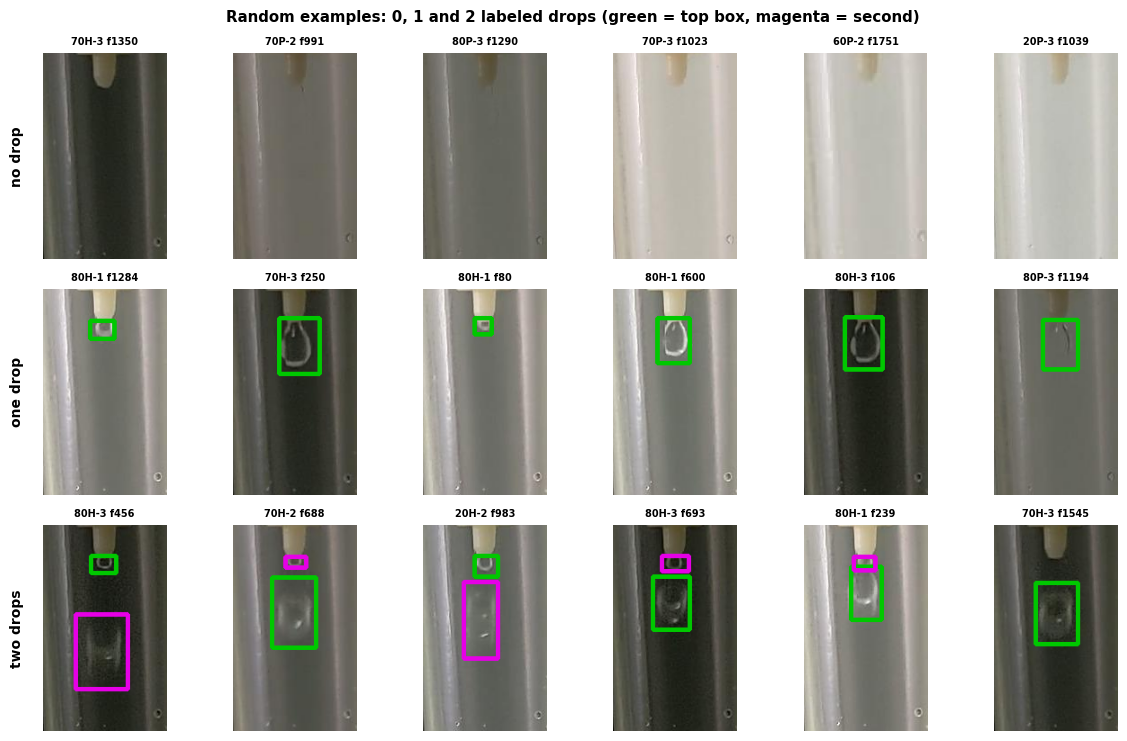

In [5]:
med_xy = df[df.n_boxes > 0].groupby("video")[["x", "y"]].median()

def crop_at(r, cx=None, cy=None, half=0.06, draw=True):
    """Fixed window around (cx, cy) (normalised); defaults to the video's usual drop position."""
    im = cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB); H, W = im.shape[:2]
    cx = med_xy.loc[r.video, "x"] if cx is None else cx
    cy = med_xy.loc[r.video, "y"] if cy is None else cy
    if draw:
        for i, (x, y, w, h) in enumerate(r.boxes):
            cv2.rectangle(im, (int((x-w/2)*W), int((y-h/2)*H)), (int((x+w/2)*W), int((y+h/2)*H)),
                          [(0, 200, 0), (230, 0, 230), (0, 160, 255)][i % 3], max(2, W // 300))
    m = int(half * H); cxp, cyp = int(cx * W), int(cy * H) + m // 2
    return im[max(0, cyp-m):cyp+m, max(0, cxp-int(0.6*m)):cxp+int(0.6*m)]

rng = np.random.default_rng(42)
fig, axes = plt.subplots(3, 6, figsize=(12, 7.5))
for row, n in enumerate([0, 1, 2]):
    pool = df[df.n_boxes == n]
    pick = pool.iloc[rng.choice(len(pool), size=min(6, len(pool)), replace=False)]
    for a in axes[row]: a.axis("off")
    for a, (_, r) in zip(axes[row], pick.iterrows()):
        a.imshow(crop_at(r)); a.set_title(f"{short(r.video)} f{r.frame}", fontsize=7)
    axes[row][0].text(-0.15, 0.5, ["no drop", "one drop", "two drops"][row], transform=axes[row][0].transAxes,
                      rotation=90, va="center", ha="right", fontsize=10, fontweight="bold")
fig.suptitle("Random examples: 0, 1 and 2 labeled drops (green = top box, magenta = second)", fontweight="bold")
plt.tight_layout(); plt.show()

**Insights**

* The dataset contains only one class, which is tetesan (drop). I renamed it to drop and set nc: 1.
* Most images contain one bounding box (approximately 98.5%), while about 1% contain no boxes and 0.4% contain two. In the two box cases, one box represents a new drop forming at the tip, while the other represents the previous drop falling. I kept both boxes because they represent valid detections. This means the counting logic must handle images with zero, one, or two drops.
* The dataset contains three image resolutions: 1080×1920 (original), 608×1081 (downscaled while maintaining the same aspect ratio), and 810×810 for one video (80P-2). Although the last resolution is a square crop, the drop proportions are similar to the other images, so I decided to keep it.

## 4. Videos: rate, background, size

In [6]:
vid = df.groupby("video").agg(
    rate=("rate", "first"), bg=("bg", "first"), frames=("frame", "count"),
    first=("frame", "min"), last=("frame", "max"),
    empty=("n_boxes", lambda s: int((s == 0).sum())), two_boxes=("n_boxes", lambda s: int((s > 1).sum())),
    in_train=("orig_split", lambda s: int((s == "train").sum())),
    in_valid=("orig_split", lambda s: int((s == "valid").sum())))
vid["span"] = vid["last"] - vid["first"] + 1
vid["coverage_in_span"] = (vid.frames / vid.span).round(2)
vid = vid.sort_values(["bg", "rate"])
print(vid.groupby(["rate", "bg"]).size().unstack(fill_value=0).rename_axis(None, axis=1).to_string(), "\n")
vid

      black  white
rate              
20        2      2
60        2      2
70        2      2
80        2      2 



,rate,bg,frames,first,last,empty,two_boxes,in_train,in_valid,span,coverage_in_span
video,,,,,,,,,,,
20H1-60s-Made-with-Clipchamp,20,black,555,0,1800,0,5,389,166,1801,0.31
20H2-60s-Made-with-Clipchamp,20,black,408,25,1657,0,2,286,122,1633,0.25
60H-2-online-video-cutter_com-,60,black,783,0,1842,8,3,355,428,1843,0.42
60H-3-online-video-cutter_com-,60,black,513,2,1853,14,1,410,103,1852,0.28
70H-2-,70,black,740,0,1828,2,6,519,221,1829,0.40
70H-3-,70,black,812,6,1832,7,7,568,244,1827,0.44
80H-1-,80,black,643,0,1842,0,4,450,193,1843,0.35
80H-3-,80,black,739,14,1787,0,7,518,221,1774,0.42
20P1-60s-Made-with-Clipchamp,20,white,359,0,1795,5,0,359,0,1796,0.20


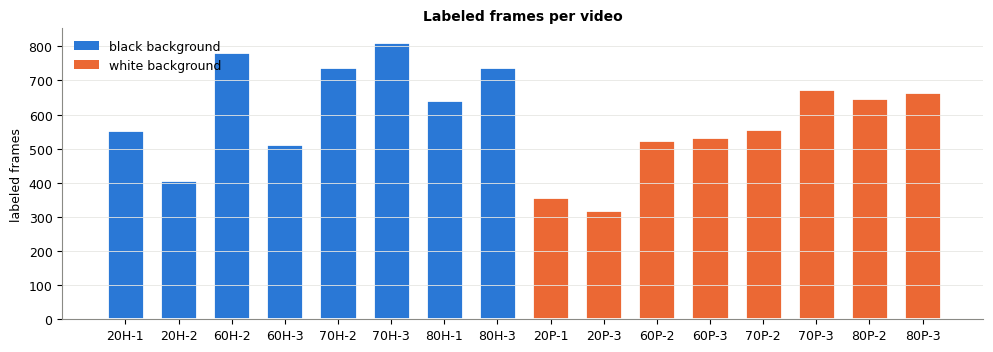

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(range(len(vid)), vid.frames, color=[BG_COLOR[b] for b in vid.bg], width=0.7, edgecolor="white", linewidth=2)
ax.set_xticks(range(len(vid)), [short(v) for v in vid.index])
ax.set_ylabel("labeled frames"); ax.set_title("Labeled frames per video")
for c, col in BG_COLOR.items(): ax.bar(0, 0, color=col, label=f"{c} background")
ax.legend(frameon=False, loc="upper left"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**Insights**

* The dataset contains 16 videos, with an equal distribution of backgrounds: 8 black and 8 white. There are two recordings for each combination of drip rate and background.
* The rates indicated in the video filenames are 20, 60, 70, and 80 DPM. Since the target range is below 40 DPM, only the four videos recorded at 20 DPM fall within this range. Therefore, additional external videos with rates between 30 and 40 DPM will be needed for testing.
* Videos with black backgrounds contain more labeled frames (approximately 410 to 810) than those with white backgrounds (approximately 320 to 670). This suggests that drops may be harder to detect against white backgrounds, which is consistent with the lower recall on white backgrounds reported in the paper.

## 5. Which frames are present? (coverage within each video's observed span)

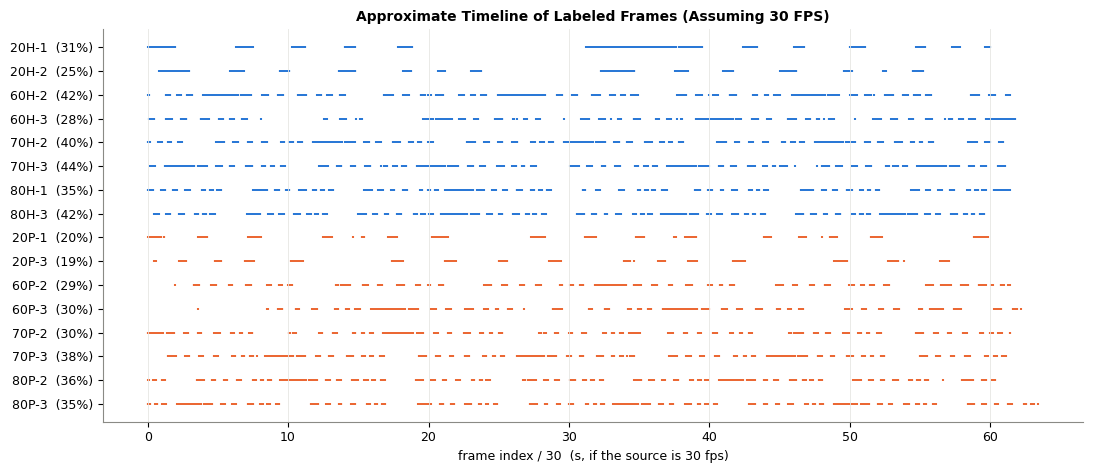

,video,runs,median_run,longest_run,consecutive_share
0,20H-1,17,23,128,0.97
1,20H-2,17,22,61,0.96
2,20P-1,23,19,35,0.94
3,20P-3,19,19,28,0.94
4,60H-2,54,12,75,0.93
5,60H-3,122,2,66,0.76
6,60P-2,55,9,68,0.90
7,60P-3,49,9,75,0.91
8,70H-2,56,10,63,0.93
9,70H-3,60,10,64,0.93


In [8]:
FPS = 30
fig, ax = plt.subplots(figsize=(11, 4.8))
for i, (v, row) in enumerate(vid.iterrows()):
    f = df.loc[df.video == v, "frame"].values
    ax.scatter(f / FPS, np.full(len(f), i), s=1.5, color=BG_COLOR[row.bg], marker="|")
ax.set_yticks(range(len(vid)), [f"{short(v)}  ({c:.0%})" for v, c in zip(vid.index, vid.coverage_in_span)])
ax.set_xlabel("frame index / 30  (s, if the source is 30 fps)")
ax.set_title("Approximate Timeline of Labeled Frames (Assuming 30 FPS)")
ax.grid(axis="y", visible=False); ax.invert_yaxis()
plt.tight_layout(); plt.show()

def runs_of(frames):
    f = np.asarray(frames); br = np.where(np.diff(f) > 1)[0]
    return np.r_[0, br + 1], np.r_[br, len(f) - 1]

runs = []
for v, g in df.groupby("video"):
    st, en = runs_of(g.frame.values); L = en - st + 1
    runs.append(dict(video=short(v), runs=len(L), median_run=int(np.median(L)), longest_run=int(L.max()),
                     consecutive_share=round((np.diff(g.frame.values) == 1).mean(), 2)))
pd.DataFrame(runs)

**Insights**

* In each video, only 18 to 44% of the frame indices between the first and last labeled frames are available. The observed frame ranges contain approximately 1,650 to 1,900 frames. For videos named "60s", this corresponds to roughly 60 seconds at 30 FPS, although the original video duration has not been confirmed.
* The labeled frames are distributed in short consecutive sequences, with a median length of 7 to 22 frames, separated by gaps. This indicates that the dataset contains selected portions of the videos rather than complete recordings.
* Since many frames are missing, the original videos cannot be reliably reconstructed, and these images alone are not sufficient for accurate drop counting. Therefore, drip rate performance must be evaluated using complete external videos.

## 6. Leakage in the original Roboflow split

In [9]:
leak = vid[["in_train", "in_valid"]].copy()
print(f"videos with frames in BOTH train and valid: {((leak.in_train > 0) & (leak.in_valid > 0)).sum()} / {len(leak)}")
df[df.video == vid.index[0]].head(8)[["video", "frame", "orig_split"]]

videos with frames in BOTH train and valid: 15 / 16


,video,frame,orig_split
0,20H1-60s-Made-with-Clipchamp,0,valid
1,20H1-60s-Made-with-Clipchamp,3,train
2,20H1-60s-Made-with-Clipchamp,4,train
3,20H1-60s-Made-with-Clipchamp,5,valid
4,20H1-60s-Made-with-Clipchamp,6,train
5,20H1-60s-Made-with-Clipchamp,7,train
6,20H1-60s-Made-with-Clipchamp,8,valid
7,20H1-60s-Made-with-Clipchamp,9,train


**Insight**

15 out of 16 videos have frames distributed between both the training and validation sets in Roboflow's original 70/30 split. Some of these frames are very close to each other, such as frame 0 in validation, frame 3 in training, and frame 5 in validation. This could make the validation mAP higher than the model's actual performance on unseen videos.

**Decision**

I decided to split the dataset by video instead of by image, so that frames from the same video stay in one split.

The test videos will not be used to make any training decisions, such as choosing hyperparameters, thresholds, or the number of epochs. These decisions will be based on the validation set only.

Since the test set contains only 2 videos, its results are not enough to confirm that the model generalizes well. Testing on complete external videos will be the main way to check its performance on unseen recordings.

## 7. The box: size and position

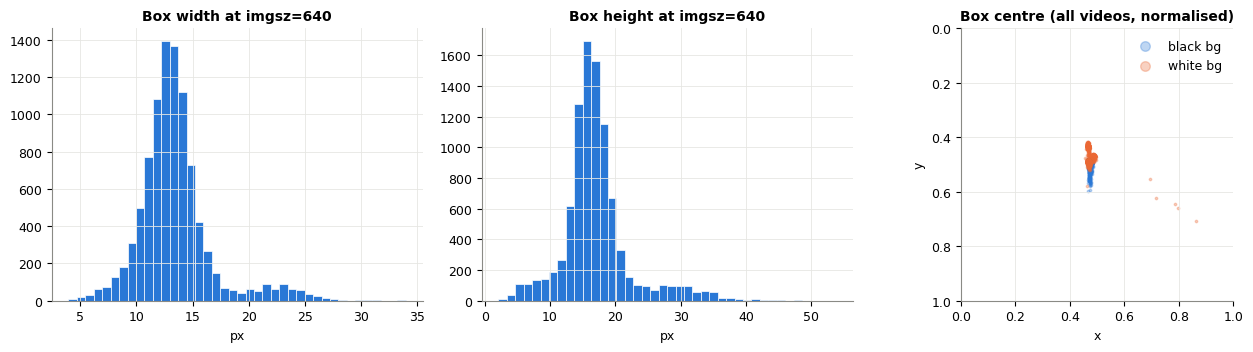

all boxes:
        count  mean  std  min   10%   50%   90%   max
w_px  9374.0  13.4  3.4  0.7  10.2  13.0  16.6  34.0
h_px  9374.0  17.0  5.4  0.0  12.2  16.4  22.3  53.7 

excluding broken boxes:
        count  mean  std  min   10%   50%   90%   max
w_px  9368.0  13.4  3.4  3.9  10.2  13.0  16.6  34.0
h_px  9368.0  17.0  5.4  2.1  12.2  16.4  22.3  53.7


video,20H-1,20H-2,20P-1,20P-3,60H-2,60H-3,60P-2,60P-3,70H-2,70H-3,70P-2,70P-3,80H-1,80H-3,80P-2,80P-3
x,0.479,0.479,0.488,0.484,0.477,0.478,0.470,0.469,0.472,0.472,0.471,0.469,0.47,0.472,0.467,0.468
y,0.491,0.490,0.470,0.469,0.490,0.490,0.491,0.492,0.490,0.490,0.491,0.490,0.49,0.490,0.433,0.490


In [10]:
pos = df[df.n_boxes > 0].copy()
s = 640 / pos[["W", "H"]].max(axis=1)                       # letterbox scale to imgsz = 640
pos["w_px"], pos["h_px"] = pos.w * pos.W * s, pos.h * pos.H * s
ok = (pos.w >= 0.004) & (pos.h >= 0.003)                      # exclude broken boxes (see §9)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].hist(pos.w_px[ok], bins=40, color=BLUE, edgecolor="white", linewidth=0.5); ax[0].set_title("Box width at imgsz=640"); ax[0].set_xlabel("px")
ax[1].hist(pos.h_px[ok], bins=40, color=BLUE, edgecolor="white", linewidth=0.5); ax[1].set_title("Box height at imgsz=640"); ax[1].set_xlabel("px")
for b, c in BG_COLOR.items():
    p = pos[pos.bg == b]; ax[2].scatter(p.x, p.y, s=3, alpha=0.3, color=c, label=f"{b} bg")
ax[2].set_xlim(0, 1); ax[2].set_ylim(1, 0); ax[2].set_aspect("equal")
ax[2].set_title("Box centre (all videos, normalised)"); ax[2].set_xlabel("x"); ax[2].set_ylabel("y")
ax[2].legend(frameon=False, markerscale=4)
plt.tight_layout(); plt.show()

pct = [.1, .5, .9]
print("all boxes:\n", pos[["w_px", "h_px"]].describe(percentiles=pct).round(1).T, "\n")
print("excluding broken boxes:\n", pos.loc[ok, ["w_px", "h_px"]].describe(percentiles=pct).round(1).T)
pos.groupby("video")[["x", "y"]].median().round(3).rename(index=short).T

**Insights**

* The median drop size is approximately 13 × 16 px at imgsz = 640, and 10% of the drops are 10 × 12 px or smaller. I used percentiles instead of the mean because some boxes have unusual sizes. The minimum values (close to 0 px) come from broken boxes, which were removed in Section 9.
* Since the drops are very small, YOLOv8n may struggle to detect some of them. For this reason, I will focus on recall rather than relying on mAP50 alone. The final evaluation will also consider counting accuracy. If recall is low, I will try cropping the drip chamber (ROI) and then increasing the image size to 960.
* The drop centres are almost in the same position across all 16 videos, with a median around (0.47, 0.49). This may cause the model to learn the drop's position instead of its actual shape.

**Training Plan**

I will compare two training experiments:

* **Experiment A:** Use the default augmentation settings.
* **Experiment B:** Use stronger translate and scale augmentation.

I will compare their recall and mAP on the validation set. However, augmentation should not move drops outside the frame or make them too small to detect. Mosaic augmentation can also make objects smaller, so I will keep scale moderate and inspect the generated `train_batch*.jpg` images.

If neither A nor B gives good results, I will try Experiment C, using an ROI crop of the drip chamber.

## 8. How the labeled drop changes over time
⚠️ This analyses the **hand drawn boxes**, not the drop itself. A box can change because the drop changed, because the annotator drew it differently, or during a hand over between two drops. Several runs from **different videos** are shown, with the frames themselves.

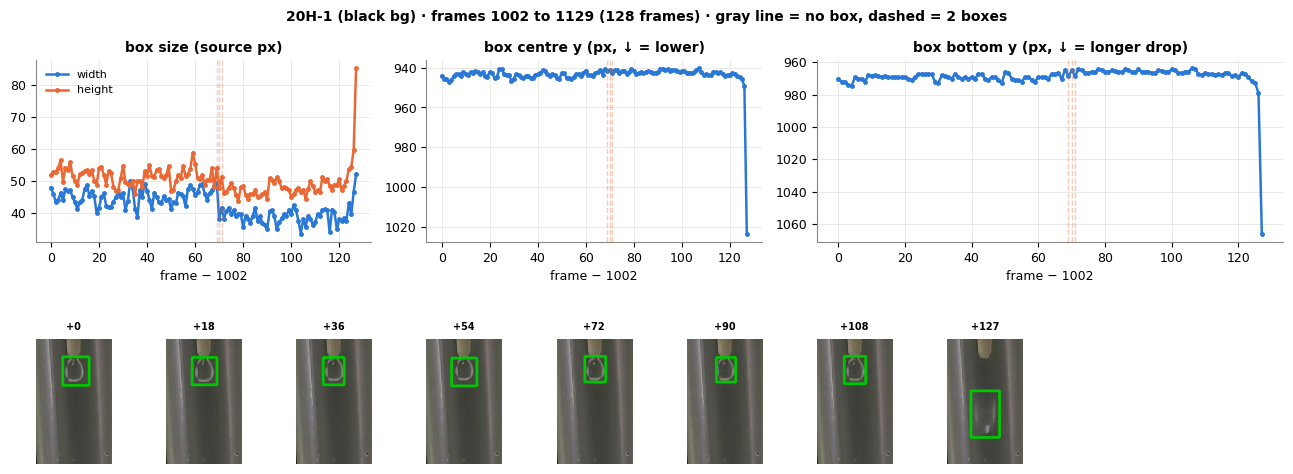

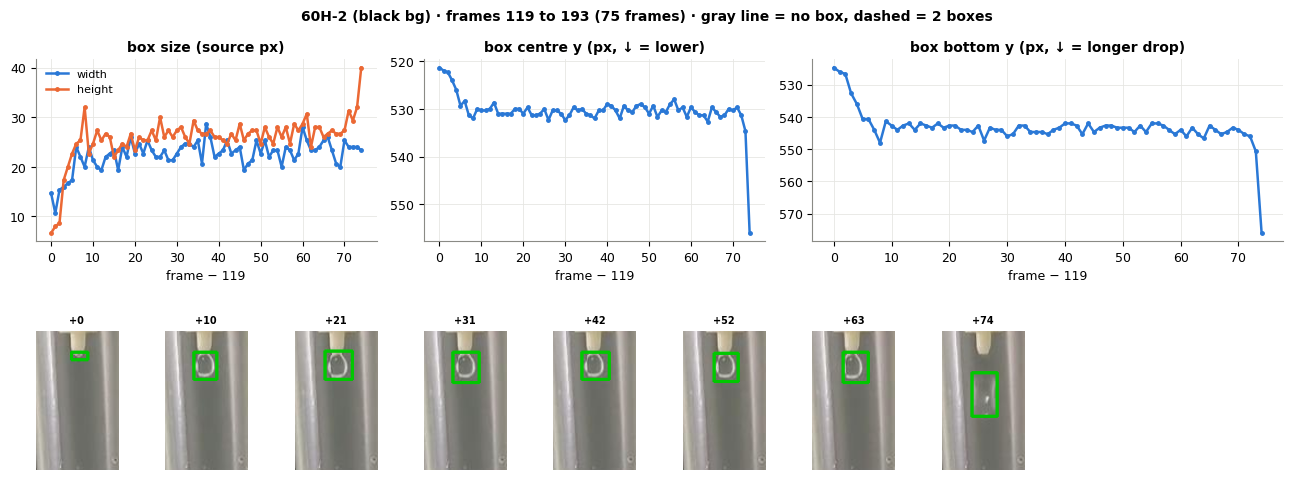

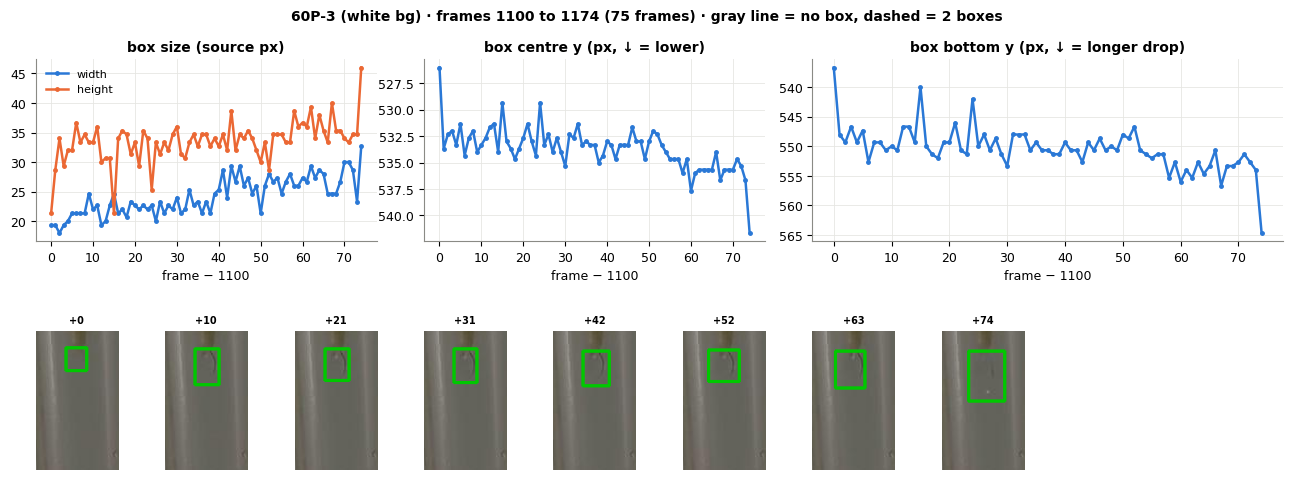

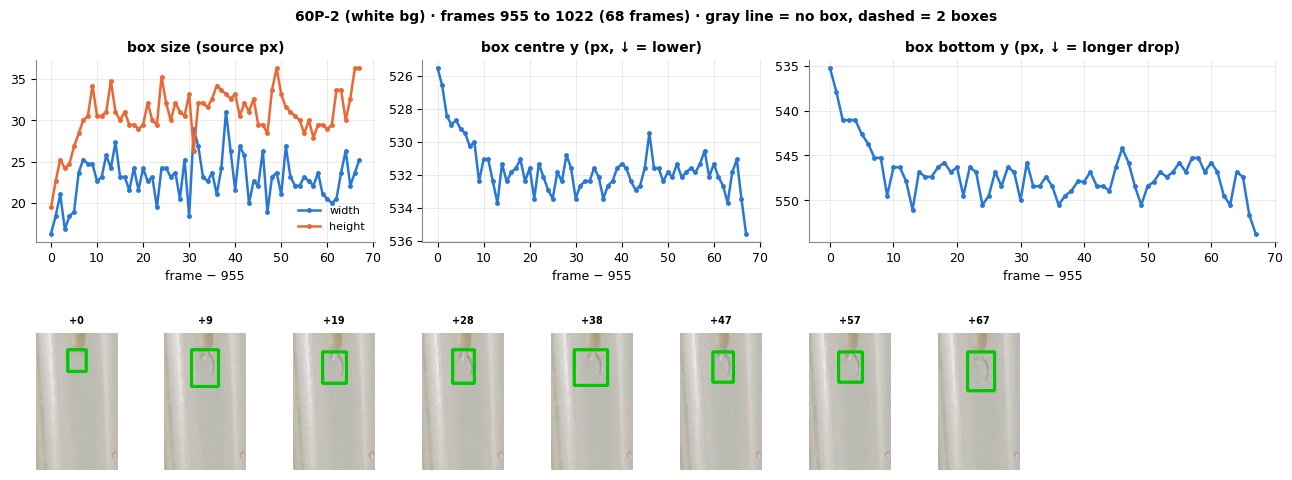

In [11]:
# longest consecutive run (empty frames included) from 4 different videos: 2 black + 2 white
cand = []
for v, g in df.groupby("video"):
    st, en = runs_of(g.frame.values); k = np.argmax(en - st)
    cand.append((en[k] - st[k] + 1, v, g.frame.values[st[k]], g.frame.values[en[k]], g.bg.iloc[0]))
cand.sort(reverse=True)
chosen = [c for c in cand if c[4] == "black"][:2] + [c for c in cand if c[4] == "white"][:2]

for L, v, f0, f1, bg in chosen:
    g = df[(df.video == v) & df.frame.between(f0, f1)]
    t = g.frame - f0; Hs = g.H.iloc[0]; Ws = g.W.iloc[0]
    fig = plt.figure(figsize=(13, 5.2)); gs = fig.add_gridspec(2, 10, height_ratios=[1, 1.15])
    a1, a2, a3 = fig.add_subplot(gs[0, 0:3]), fig.add_subplot(gs[0, 3:6]), fig.add_subplot(gs[0, 6:10])
    a1.plot(t, g.w * Ws, "-o", ms=2.5, lw=1.8, color=BLUE, label="width")
    a1.plot(t, g.h * Hs, "-o", ms=2.5, lw=1.8, color=ORANGE, label="height")
    a1.set_title("box size (source px)"); a1.legend(frameon=False, fontsize=8)
    a2.plot(t, g.y * Hs, "-o", ms=2.5, lw=1.8, color=BLUE); a2.invert_yaxis(); a2.set_title("box centre y (px, ↓ = lower)")
    a3.plot(t, g.y_bottom * Hs, "-o", ms=2.5, lw=1.8, color=BLUE); a3.invert_yaxis(); a3.set_title("box bottom y (px, ↓ = longer drop)")
    for a in (a1, a2, a3):
        a.set_xlabel(f"frame − {f0}")
        for e in t[g.n_boxes == 0]: a.axvline(e, color=GRAY, alpha=0.5, lw=1)       # no box
        for e in t[g.n_boxes > 1]: a.axvline(e, color=ORANGE, alpha=0.35, lw=1, ls="--")   # 2 boxes
    idx = np.unique(np.r_[np.linspace(0, len(g) - 1, 8).astype(int), len(g) - 1])[-10:]
    for j, i in enumerate(idx):
        a = fig.add_subplot(gs[1, j]); r = g.iloc[i]
        a.imshow(crop_at(r)); a.axis("off"); a.set_title(f"+{r.frame - f0}" + (" (no box)" if r.n_boxes == 0 else ""), fontsize=7)
    fig.suptitle(f"{short(v)} ({bg} bg) · frames {f0} to {f1} ({L} frames) · gray line = no box, dashed = 2 boxes",
                 fontweight="bold", fontsize=10)
    plt.tight_layout(); plt.show()

**Observations (from the labels)**
* In the long runs, the tip box **forms** in a few frames, **hangs** with small changes for most of the run, then **stretches** (height and bottom edge jump) and is **replaced** by a new small drop, sometimes with a frame that has 2 boxes in between.
* The centre barely moves until the last frames → Hegde's rule *"track disappears after moving ≥ 10 px down"* would miss most of these drops.

**Status: hypothesis, not a final decision.** It is based on manual boxes and a few runs. It will be **confirmed or rejected on YOLO predictions over complete videos**, where detection jitter and brief missed detections also appear. The counting logic will therefore be a small **state machine** (no drop → forming → detached → count & rearm) that requires the drop to persist for several frames and ignores short detection dropouts, rather than reacting to a single frame.

**Design parameter, not a data finding:** a minimum **0.4 s** between counted drops = at most **150 dpm**. Chosen because > 200 dpm is treated as free flow (🔴) anyway. It will be tuned on validation videos.

## 9. Label quality
Each box is classified as:
* **tip drop**: the topmost box near the video's usual drop position (valid).
* **falling drop**: a second box directly **below** the tip box (|Δx| < 0.03 and 0 < Δy < 0.15) → valid, **kept**.
* **annotation error**: zero width or height (**broken**), or **far from the chamber** (|x − median| > 0.15 or |y − median| > 0.25: a falling drop stays in the tip column and inside the chamber, so it can't be this far).
* **polygon** (converted) and **duplicate** (two boxes with IoU > 0.5 on one drop).

In [12]:
def iou(a, b):
    ax1, ay1, ax2, ay2 = a[0]-a[2]/2, a[1]-a[3]/2, a[0]+a[2]/2, a[1]+a[3]/2
    bx1, by1, bx2, by2 = b[0]-b[2]/2, b[1]-b[3]/2, b[0]+b[2]/2, b[1]+b[3]/2
    i = max(0, min(ax2, bx2) - max(ax1, bx1)) * max(0, min(ay2, by2) - max(ay1, by1))
    return i / (a[2]*a[3] + b[2]*b[3] - i + 1e-9)

# ── the rules (same thresholds as prepare_data.py) ──
def is_broken(b):        return b[2] < 0.004 or b[3] < 0.003
def is_far(b, video):    return abs(b[0] - med_xy.loc[video, "x"]) > 0.15 or abs(b[1] - med_xy.loc[video, "y"]) > 0.25
def dedupe_keep(boxes):  # indices to keep: largest first, drop any box overlapping a kept one by IoU > 0.5
    keep = []
    for i in sorted(range(len(boxes)), key=lambda i: -boxes[i][2] * boxes[i][3]):
        if all(iou(boxes[i], boxes[j]) <= 0.5 for j in keep): keep.append(i)
    return sorted(keep)

def classify(r):
    tags = []
    if r.polygon: tags.append("polygon")
    top = min(r.boxes, key=lambda b: b[1] - b[3] / 2) if r.boxes else None
    for b in r.boxes:
        if is_broken(b): tags.append("error: broken")
        elif is_far(b, r.video): tags.append("error: far from chamber")
        elif b is not top and abs(b[0] - top[0]) < 0.03 and 0 < b[1] - top[1] < 0.15: tags.append("falling drop (valid)")
    if len(dedupe_keep(r.boxes)) < r.n_boxes:
        tags.append("duplicate")
    return tags

df["tags"] = df.apply(classify, axis=1)
counts = pd.Series([t for ts in df.tags for t in set(ts)]).value_counts()
print(counts.to_string())
df[df.tags.apply(lambda ts: any(t != "falling drop (valid)" for t in ts))][["video", "frame", "tags", "n_boxes"]]

falling drop (valid)       36
error: broken               7
polygon                     7
duplicate                   3
error: far from chamber     1


,video,frame,tags,n_boxes
311,20H1-60s-Made-with-Clipchamp,1071,[duplicate],2
312,20H1-60s-Made-with-Clipchamp,1072,"[falling drop (valid), duplicate]",2
313,20H1-60s-Made-with-Clipchamp,1073,[duplicate],2
989,20P1-60s-Made-with-Clipchamp,28,[error: broken],1
1059,20P1-60s-Made-with-Clipchamp,439,[error: broken],1
1251,20P1-60s-Made-with-Clipchamp,1440,[error: broken],1
1844,60H-2-online-video-cutter_com-,415,[polygon],1
1845,60H-2-online-video-cutter_com-,416,[polygon],1
1846,60H-2-online-video-cutter_com-,417,[polygon],1
1847,60H-2-online-video-cutter_com-,418,[polygon],1


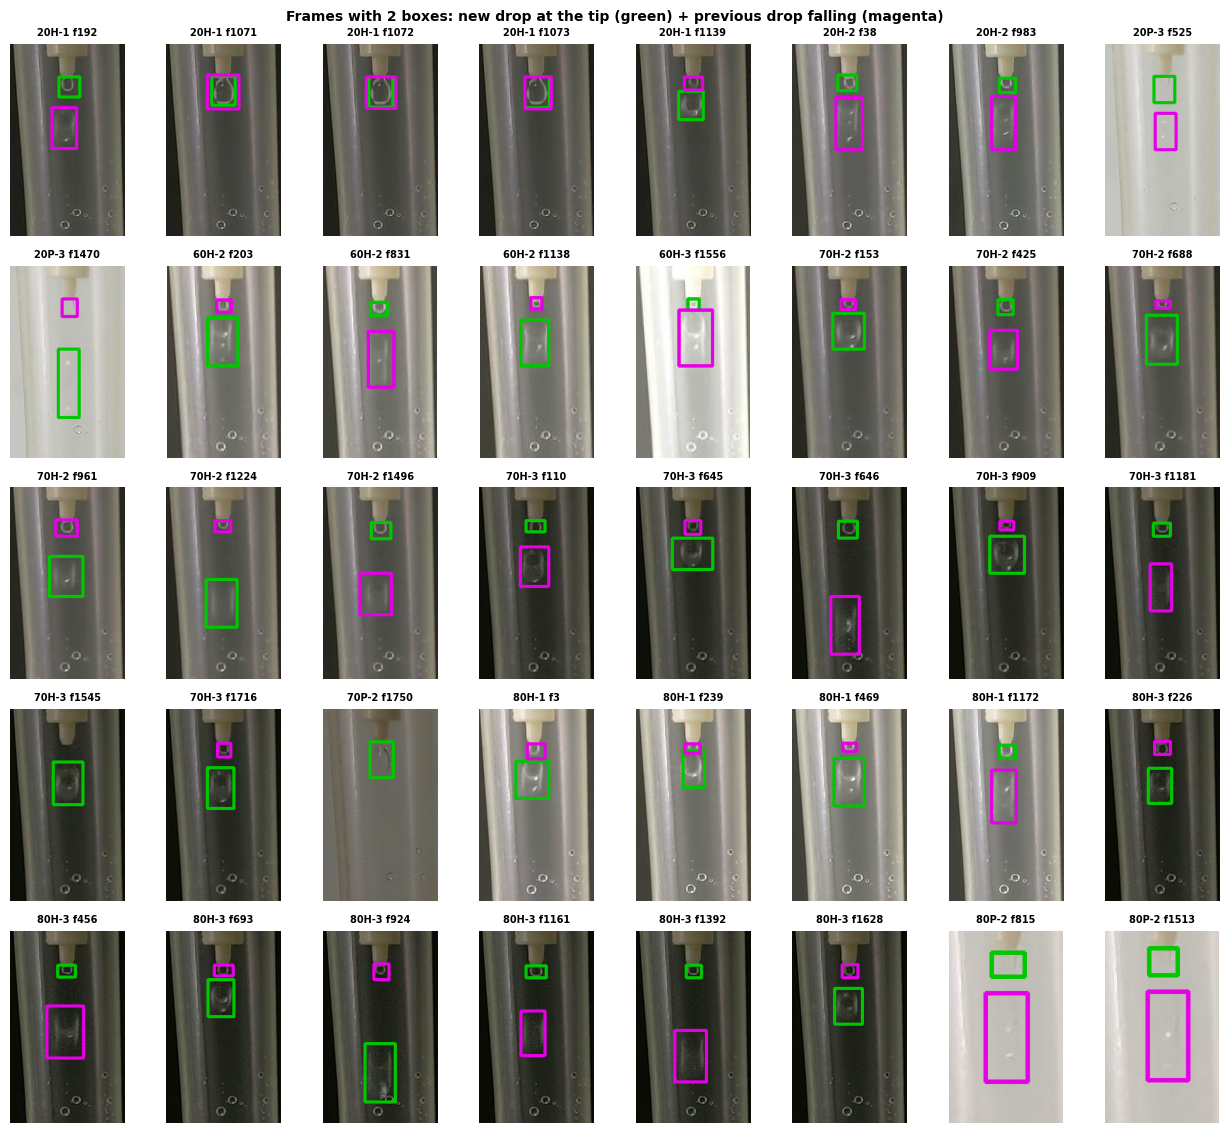

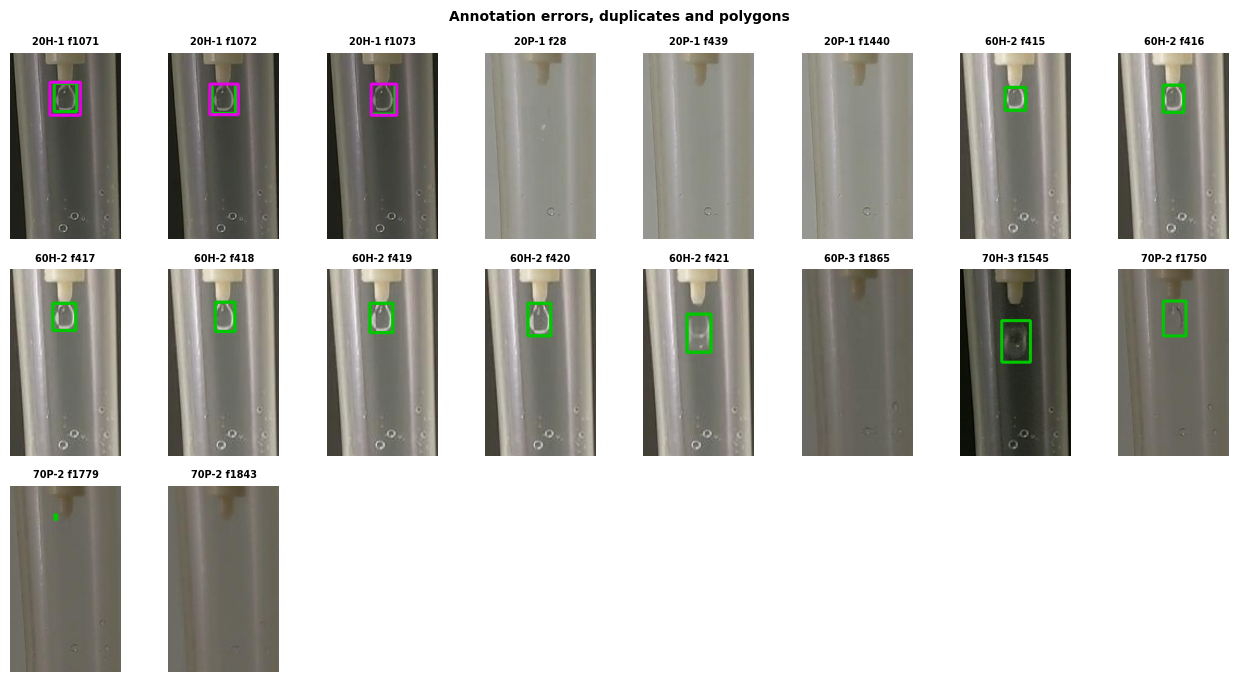

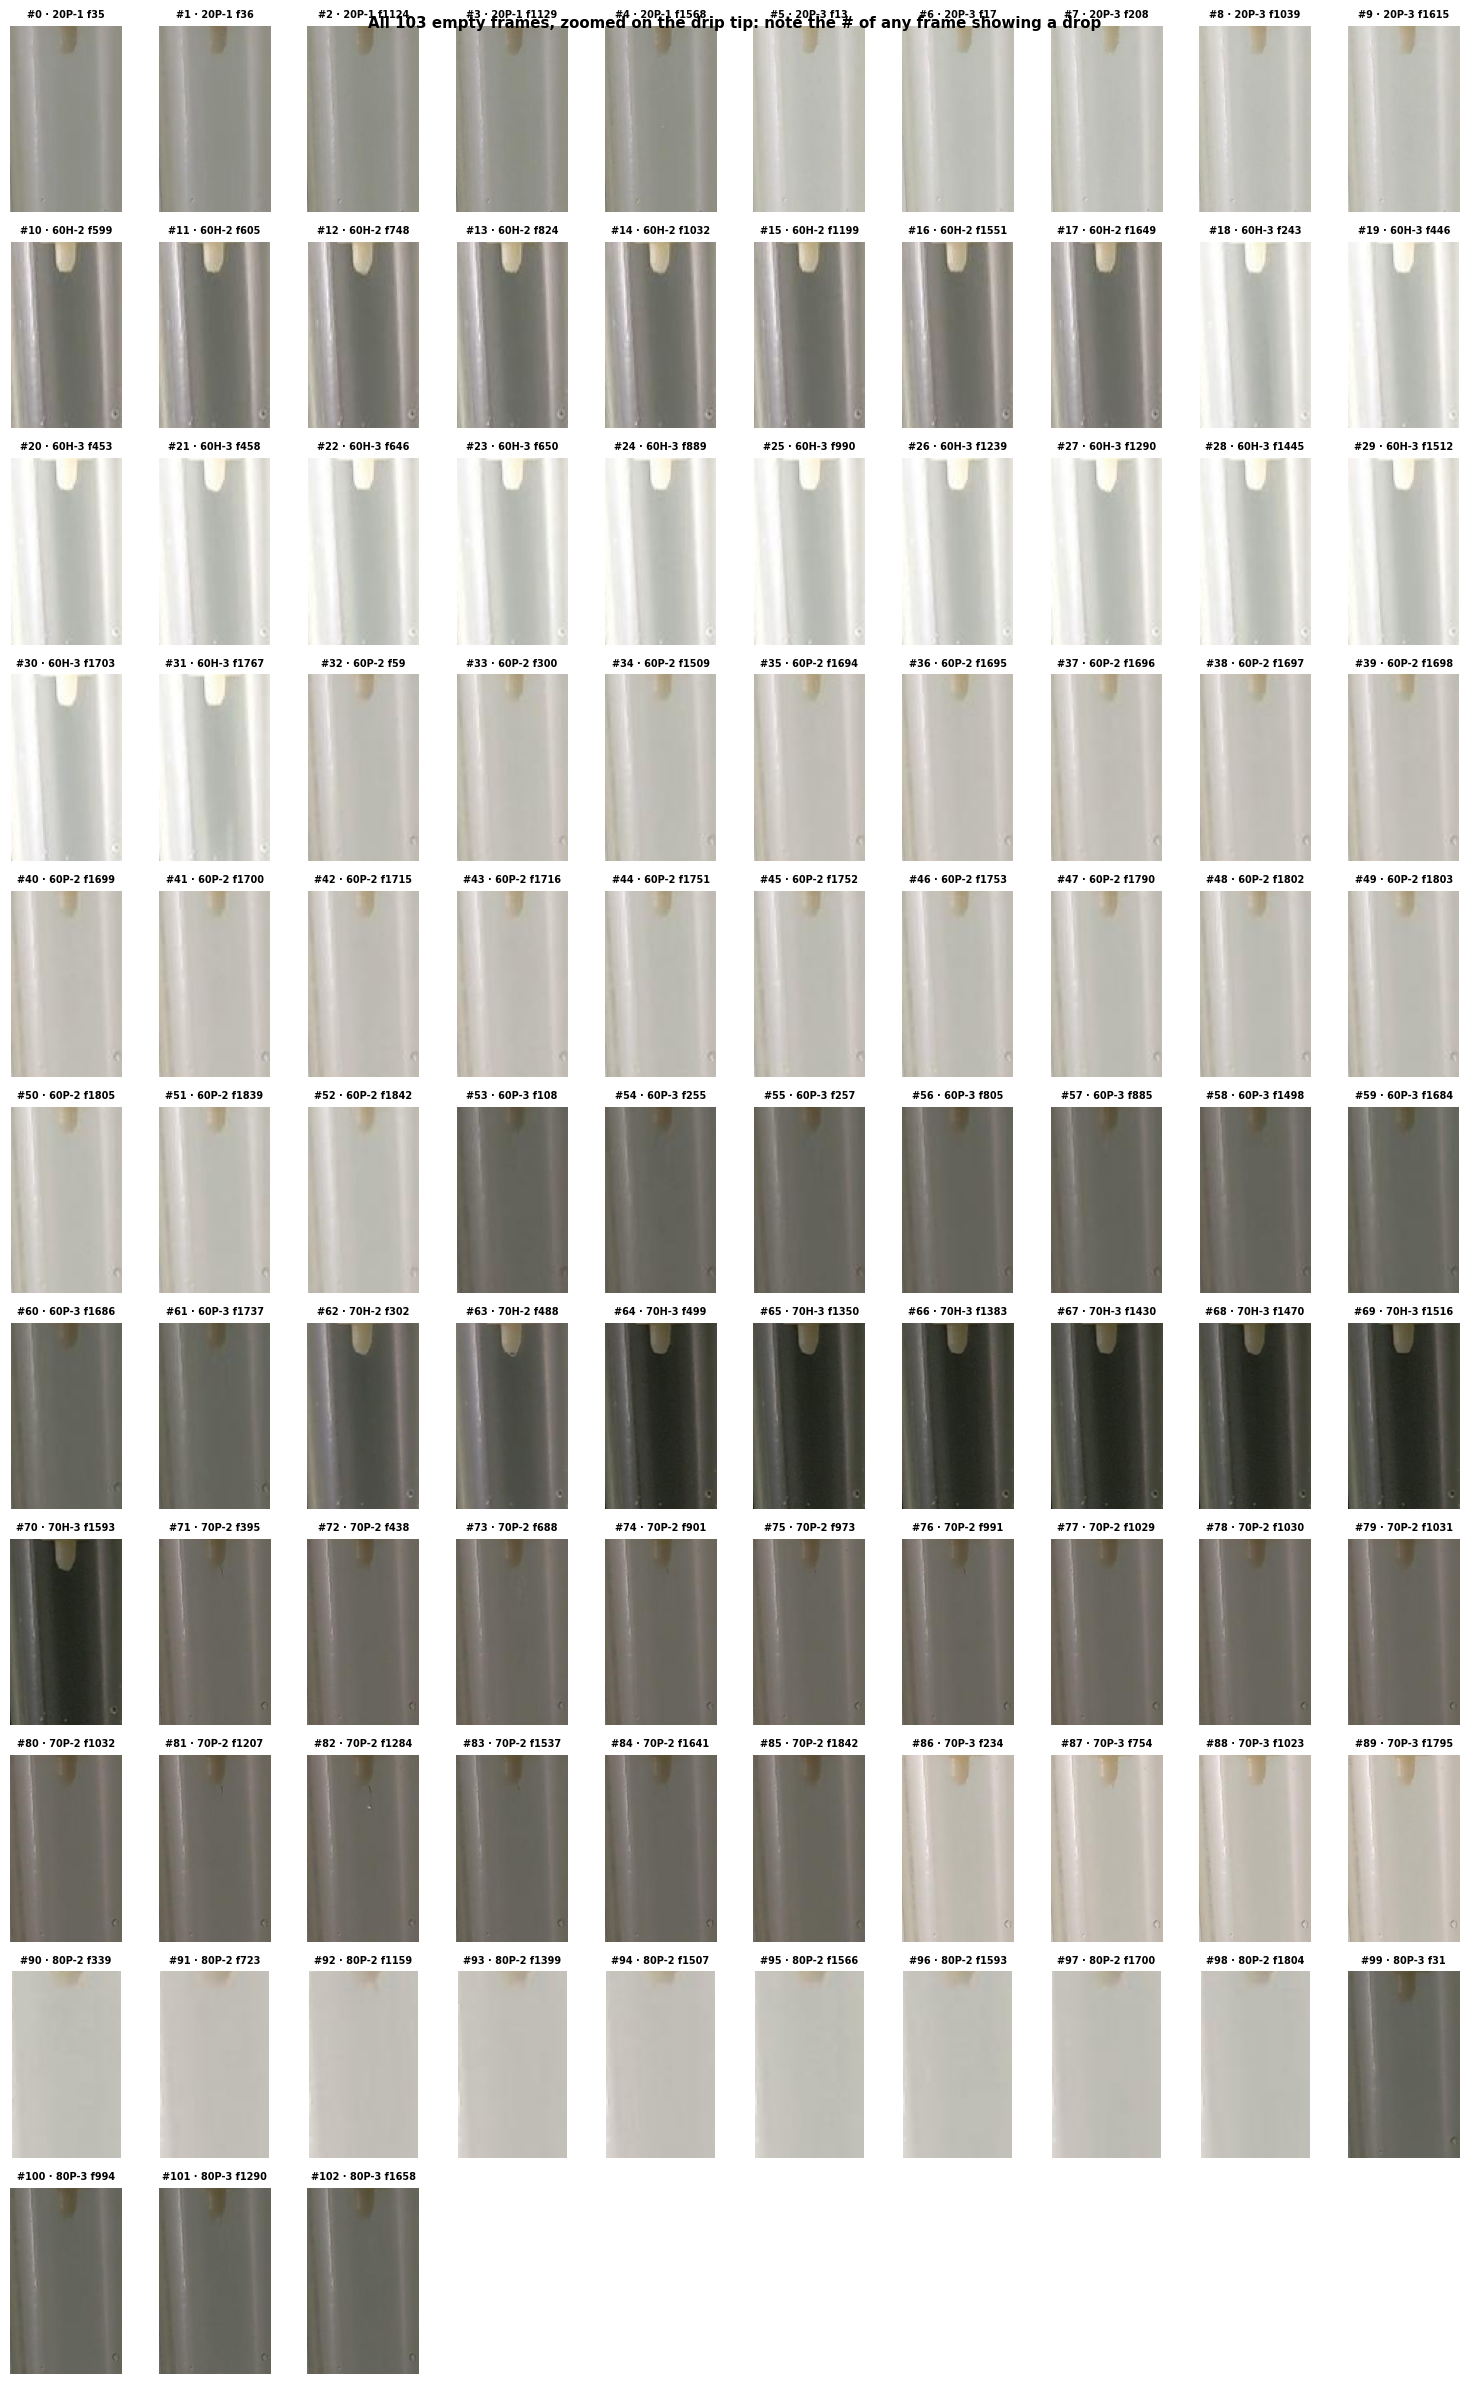

In [13]:
def grid(rows, title, cols=8):
    n = len(rows); rr = max(1, (n + cols - 1) // cols)
    fig, axes = plt.subplots(rr, cols, figsize=(cols * 1.6, rr * 2.3), squeeze=False)
    for a in axes.flat: a.axis("off")
    for a, (_, r) in zip(axes.flat, rows.iterrows()):
        a.imshow(crop_at(r, half=0.08)); a.set_title(f"{short(r.video)} f{r.frame}", fontsize=7)
    fig.suptitle(title, fontsize=10, fontweight="bold"); plt.tight_layout(); plt.show()

grid(df[df.n_boxes > 1], "Frames with 2 boxes: new drop at the tip (green) + previous drop falling (magenta)")
problems = df[df.tags.apply(lambda ts: any(t.startswith("error") or t in ("duplicate", "polygon") for t in ts))]
if len(problems): grid(problems, "Annotation errors, duplicates and polygons")

# Review ALL empty frames zoomed on the drip tip; note the # of any frame that shows a drop
empties = df[df.n_boxes == 0].reset_index(drop=True)
cols = 10; rows_ = (len(empties) + cols - 1) // cols
fig, axes = plt.subplots(rows_, cols, figsize=(cols * 1.5, rows_ * 2.2), squeeze=False)
for a in axes.flat: a.axis("off")
for i, (a, (_, r)) in enumerate(zip(axes.flat, empties.iterrows())):
    a.imshow(crop_at(r, half=0.06)); a.set_title(f"#{i} · {short(r.video)} f{r.frame}", fontsize=7)
fig.suptitle(f"All {len(empties)} empty frames, zoomed on the drip tip: note the # of any frame showing a drop",
             fontweight="bold")
plt.tight_layout(); plt.show()

**Insights**

* **Frames with 2 boxes:** We found frames with two boxes representing a new drop forming at the tip and the previous drop falling below it. We considered these valid and kept both boxes because they provide useful examples of falling drops.
* **Duplicates (3, 20H-1, frames 1071 to 1073):** We found three cases where two boxes were placed around the same drop. We kept the larger box and removed the duplicate.
* **Polygons (7, 60H-2, frames 415 to 421):** We found seven polygon annotations and converted them into bounding boxes.
* **Annotation errors (8):** We identified eight errors: seven broken boxes with nearly zero width or height, and one box located far outside the chamber. These images were removed during the `prepare_data.py` step.
* **Empty frames:** We reviewed all 113 empty frames in the original dataset, zoomed on the drip tip. 11 of them (about 10%) showed a visible drop next to labeled neighbours. We annotated the 7 clearest ones in our Roboflow fork. We removed the other 4: 3 small drops that were hard to box reliably (70H-2 f1254, 80H-1 f1301, 80H-3 f1249) and 1 ambiguous frame (80P-3 f1290). This way visible drops are not treated as background. The remaining 102 empty frames are confirmed negatives.

### Check of the frames I annotated in Roboflow
These 7 frames had a visible drop but no box in the original dataset. I added the boxes in my fork. Each one is shown between its labeled neighbours, so the new box can be compared with the boxes before and after it.

found 7 / 7, with a box: 7
removed in fork, still present: 0


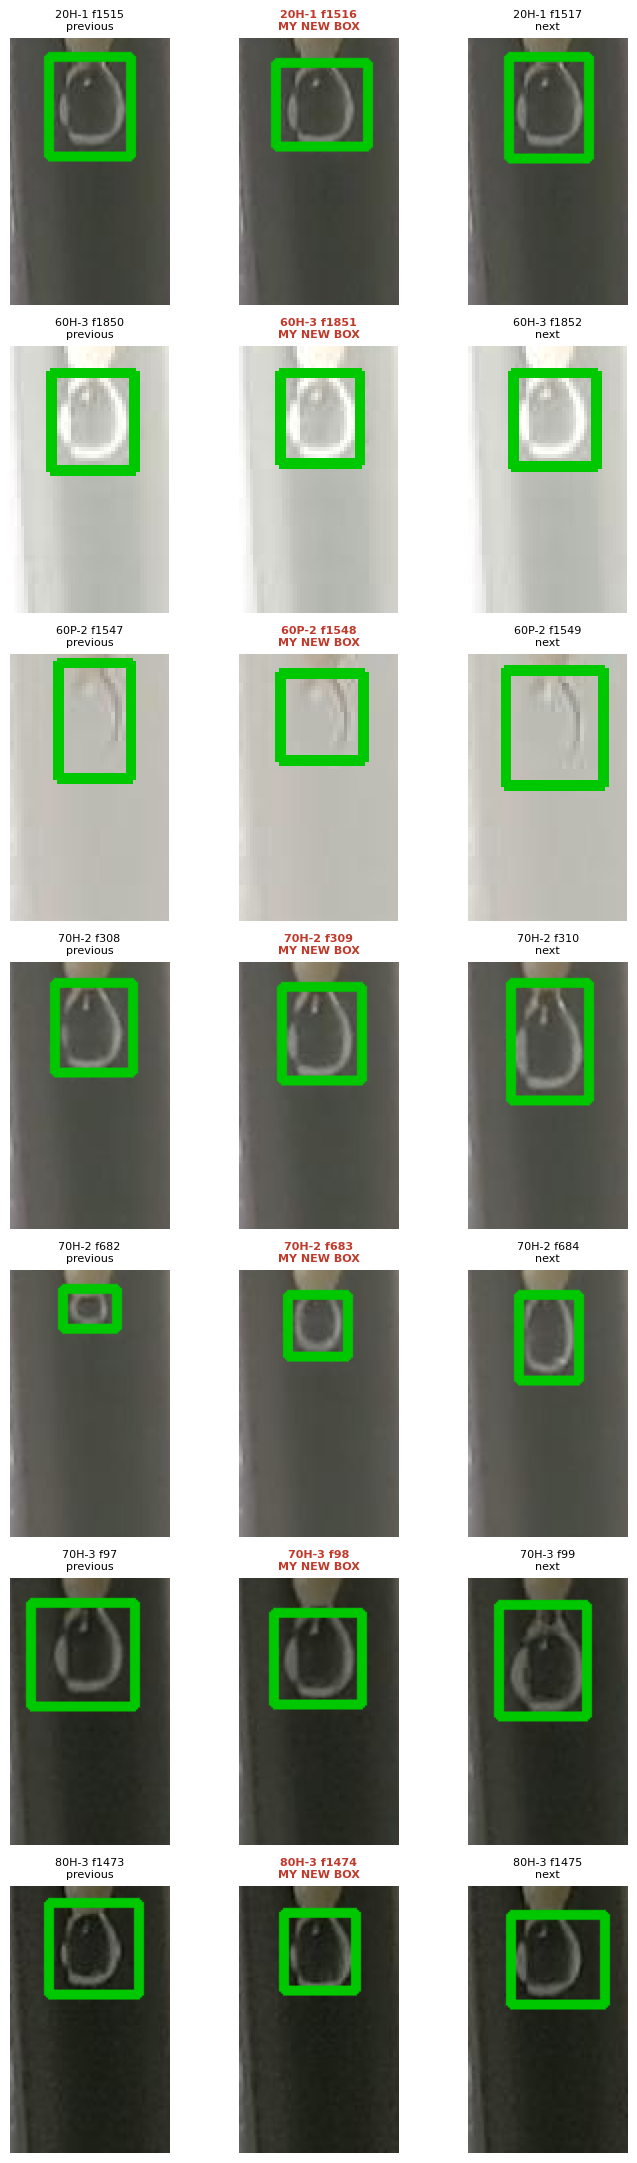

In [14]:
FIXED = ["20H1-60s-Made-with-Clipchamp_mp4-1516", "60H-3-online-video-cutter_com-_mp4-1851",
         "60P-2-online-video-cutter_com-_mp4-1548", "70H-2-_mp4-309", "70H-2-_mp4-683",
         "70H-3-_mp4-98", "80H-3-_mp4-1474"]
REMOVED_IN_FORK = ["70H-2-_mp4-1254", "80H-1-_mp4-1301", "80H-3-_mp4-1249"]
df["key"] = df.video + "_mp4-" + df.frame.astype(str)
fixed = df[df.key.isin(FIXED)]
print(f"found {len(fixed)} / {len(FIXED)}, with a box: {(fixed.n_boxes > 0).sum()}")
print("removed in fork, still present:", df.key.isin(REMOVED_IN_FORK).sum())

def nearest(r, side):
    g = df[(df.video == r.video) & (df.n_boxes > 0) & (df.key != r.key)]
    g = g[g.frame < r.frame].tail(1) if side < 0 else g[g.frame > r.frame].head(1)
    return None if g.empty else g.iloc[0]

fig, axes = plt.subplots(len(fixed), 3, figsize=(7.5, len(fixed) * 3.1), squeeze=False)
for row, (_, r) in enumerate(fixed.iterrows()):
    for col, (rr, cap) in enumerate([(nearest(r, -1), "previous"), (r, "MY NEW BOX"), (nearest(r, +1), "next")]):
        a = axes[row][col]; a.axis("off")
        if rr is None: continue
        a.imshow(crop_at(rr, half=0.035))
        a.set_title(f"{short(rr.video)} f{rr.frame}\n{cap}", fontsize=8,
                    fontweight="bold" if col == 1 else "normal", color="#c0392b" if col == 1 else "black")
plt.tight_layout(); plt.show()

### Preview of every fix (dry run, nothing is changed)
Each fix is drawn on the image **before** it is applied, using the same rule functions as the cleaning step:
* **Duplicate:** *before* = all boxes (white, yellow), *after* = only the kept box (green, the largest).
* **Polygon:** *before* = the original polygon (yellow points), *after* = the box that replaces it (green).
* **Broken / far box:** red = the faulty box, green = other boxes → **the whole image is removed** by `prepare_data.py`.
* **Unlabeled drop:** the image is removed (it shows a drop but has no box).

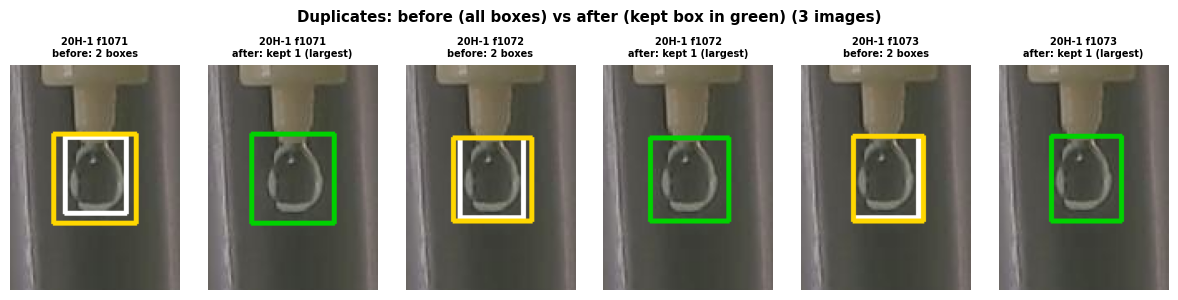

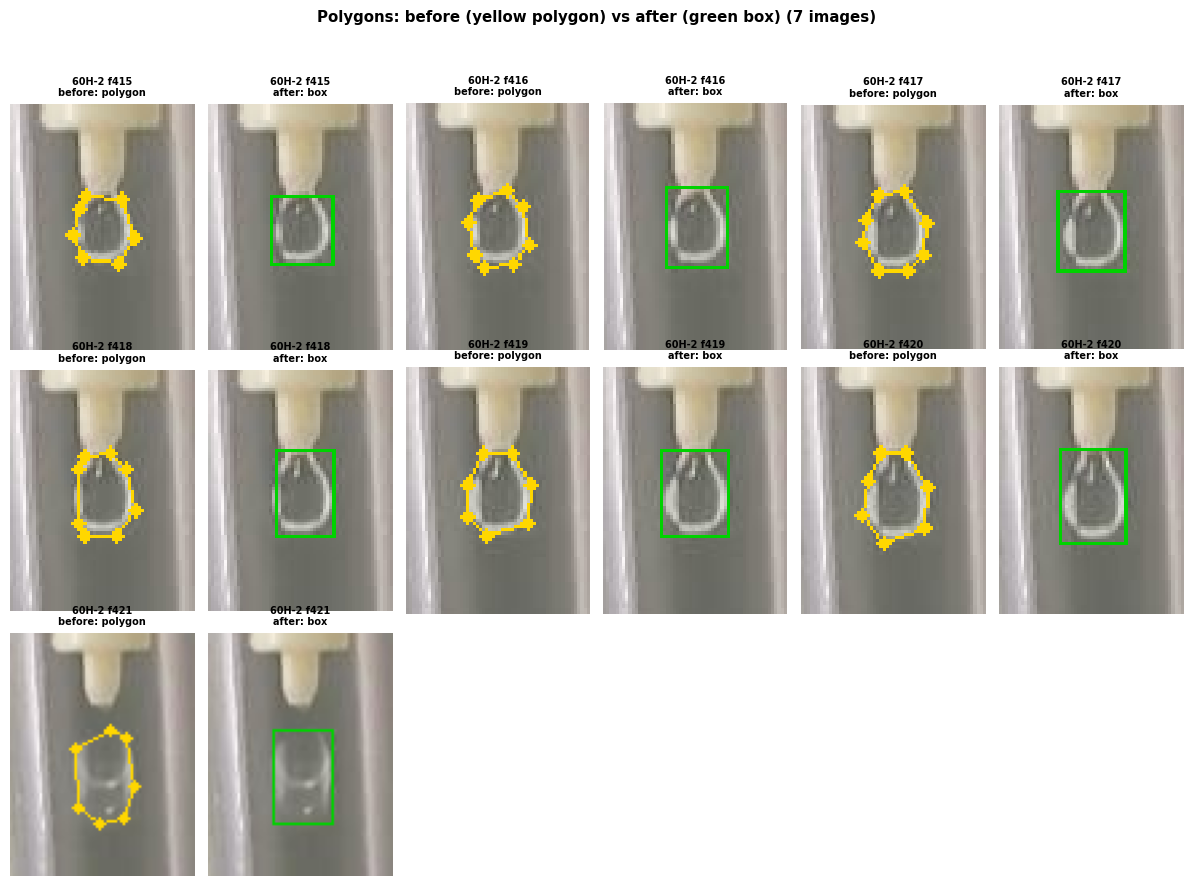

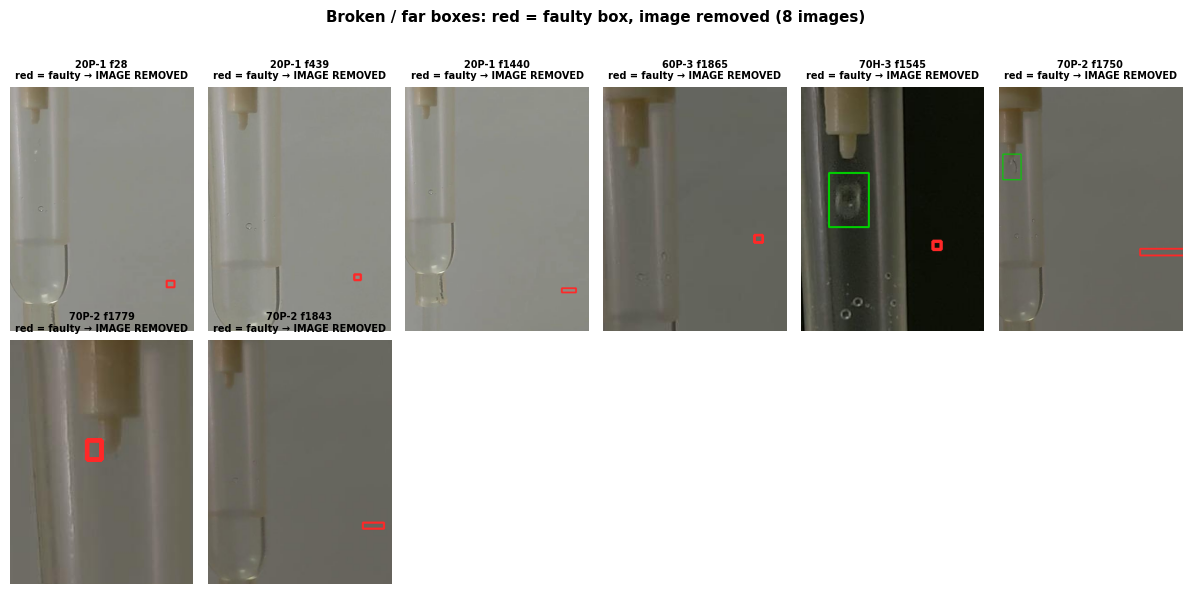

In [15]:
GREEN, RED, YELLOW, WHITE = (0, 210, 0), (255, 40, 40), (255, 215, 0), (255, 255, 255)

def px(b, W, H):
    x, y, w, h = b
    return int((x - w/2) * W), int((y - h/2) * H), int((x + w/2) * W), int((y + h/2) * H)

def raw_polygons(label):
    out = []
    for line in Path(label).read_text().splitlines():
        v = line.split()
        if len(v) > 5: nums = list(map(float, v[1:])); out.append(list(zip(nums[0::2], nums[1::2])))
    return out

def zoom(im, r, boxes, min_half=0.035, pad=0.02):
    """Crop around the given boxes + the usual drop position (keeps far boxes visible)."""
    H, W = im.shape[:2]
    xs = [b[0] for b in boxes] + [med_xy.loc[r.video, "x"]]; ys = [b[1] for b in boxes] + [med_xy.loc[r.video, "y"]]
    cx, cy = (min(xs) + max(xs)) / 2 * W, (min(ys) + max(ys)) / 2 * H
    half = max((max(xs) - min(xs)) * W, (max(ys) - min(ys)) * H) / 2 + max(min_half, pad) * H
    return im[int(max(0, cy - half)):int(cy + half), int(max(0, cx - 0.75 * half)):int(cx + 0.75 * half)]

def preview(r, kind):
    """→ list of (panel, caption); 'before' and 'after' panels where the fix changes the boxes."""
    base = cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB); H, W = base.shape[:2]; t = max(1, W // 500)
    before, after = base.copy(), base.copy()
    if kind == "duplicate":
        keep = dedupe_keep(r.boxes)
        for i, b in enumerate(r.boxes):
            p = px(b, W, H)
            cv2.rectangle(before, p[:2], p[2:], [WHITE, YELLOW, RED][i % 3], t)
            if i in keep: cv2.rectangle(after, p[:2], p[2:], GREEN, t)
        return [(zoom(before, r, r.boxes), f"before: {r.n_boxes} boxes"),
                (zoom(after, r, r.boxes), f"after: kept {len(keep)} (largest)")]
    if kind == "polygon":
        for poly in raw_polygons(r.label):
            pts = np.array([(int(x * W), int(y * H)) for x, y in poly], np.int32)
            cv2.polylines(before, [pts], True, YELLOW, t)
            for q in pts: cv2.circle(before, (int(q[0]), int(q[1])), t + 1, YELLOW, -1)
        for b in r.boxes: p = px(b, W, H); cv2.rectangle(after, p[:2], p[2:], GREEN, t)
        return [(zoom(before, r, r.boxes), "before: polygon"), (zoom(after, r, r.boxes), "after: box")]
    if kind == "error":
        for b in r.boxes:
            bad = is_broken(b) or is_far(b, r.video); p = px(b, W, H)
            cv2.rectangle(before, (p[0] - 3*t, p[1] - 3*t), (max(p[2], p[0]) + 3*t, max(p[3], p[1]) + 3*t),
                          RED if bad else GREEN, t + 1 if bad else t)
        return [(zoom(before, r, r.boxes, min_half=0.06), "red = faulty → IMAGE REMOVED")]
    if kind == "unlabeled":
        return [(zoom(before, r, [], min_half=0.035), "no box, drop visible? → IMAGE REMOVED")]

def preview_grid(rows, kind, title, cols=6):
    if len(rows) == 0: print(f"{title}: none"); return
    panels = [(r, p) for _, r in rows.iterrows() for p in preview(r, kind)]
    rr = (len(panels) + cols - 1) // cols
    fig, axes = plt.subplots(rr, cols, figsize=(cols * 2.0, rr * 3.0), squeeze=False)
    for a in axes.flat: a.axis("off")
    for a, (r, (img, cap)) in zip(axes.flat, panels):
        a.imshow(img); a.set_title(f"{short(r.video)} f{r.frame}\n{cap}", fontsize=7)
    fig.suptitle(f"{title} ({len(rows)} images)", fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()

has = lambda tag: df[df.tags.apply(lambda ts: any(t.startswith(tag) for t in ts))]
preview_grid(has("duplicate"), "duplicate", "Duplicates: before (all boxes) vs after (kept box in green)")
preview_grid(has("polygon"), "polygon", "Polygons: before (yellow polygon) vs after (green box)")
preview_grid(has("error"), "error", "Broken / far boxes: red = faulty box, image removed")

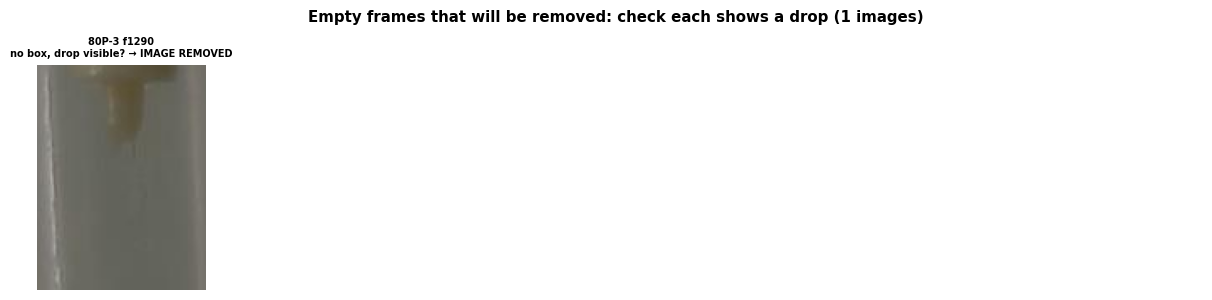

Images to exclude:
  80P-3-_mp4-1290


In [16]:
# Unlabeled drops: fill DROP_SEEN with the # numbers from the empty-frame review above, then preview them
DROP_SEEN = []   # # numbers from the empty frame review that still show a drop
KNOWN = ["80P-3-_mp4-1290"]   # ambiguous frame: faint drop on white, can't be boxed reliably
UNLABELED = sorted(set(KNOWN + [f"{empties.loc[i, 'video']}_mp4-{empties.loc[i, 'frame']}" for i in DROP_SEEN]))
to_drop = empties[empties.apply(lambda r: f"{r.video}_mp4-{r.frame}" in UNLABELED, axis=1)]
preview_grid(to_drop, "unlabeled", "Empty frames that will be removed: check each shows a drop")
print("Images to exclude:", *UNLABELED, sep="\n  ")

### Cleaning on a copy
`RAW` stays untouched. `CLEAN` = copy of `RAW` (images hard linked, labels copied) where the fixes are applied. Statistics are then **recomputed** from `CLEAN`.

In [17]:
# 1) fresh working copy
if os.path.exists(CLEAN): shutil.rmtree(CLEAN)
shutil.copytree(RAW, CLEAN, copy_function=lambda s, d: os.link(s, d) if s.endswith((".jpg", ".png")) else shutil.copy2(s, d))

# 2) remove empty frames that actually show a drop (previewed above)
# UNLABELED was set and previewed in the cell above
for name in UNLABELED:
    for p in glob.glob(f"{CLEAN}/**/{glob.escape(name)}_*", recursive=True):
        os.remove(p); print("removed", Path(p).name[:60])

# 3) de-duplicate overlapping boxes (keep the larger)
fixed = 0
for _, r in df[df.tags.apply(lambda ts: "duplicate" in ts)].iterrows():
    lab = Path(r.label.replace(RAW, CLEAN, 1))
    lines = [l for l in lab.read_text().splitlines() if l.strip()]
    lab.write_text("\n".join(lines[i] for i in dedupe_keep(r.boxes))); fixed += 1
print("de-duplicated:", fixed, "label files")
# polygons → boxes and broken / far boxes are handled by prepare_data.py

# 4) re-load so every later number reflects the cleaned data
df_raw, df = df, load(CLEAN)
print(f"RAW: {len(df_raw)} images · CLEAN: {len(df)} images · boxes per image now:",
      df.n_boxes.value_counts().sort_index().to_dict())

removed 80P-3-_mp4-1290_jpg.rf.2523392f409a09cecc1fdfa86df79a31.jpg
removed 80P-3-_mp4-1290_jpg.rf.2523392f409a09cecc1fdfa86df79a31.txt
de-duplicated: 3 label files
RAW: 9477 images · CLEAN: 9476 images · boxes per image now: {0: 102, 1: 9337, 2: 37}


## 10. Build the training set
[`prepare_data.py`](../src/prepare_data.py) (upload to `/content` first). It:
1. converts polygons → boxes and drops images with broken or far boxes (same rules as §9).
2. renames the class to `drop`.
3. splits **by video** into 11 / 3 / 2 videos, with both backgrounds in every split and seed 42.
4. writes `data.yaml` and `check_boxes.jpg`.

In [18]:
!python prepare_data.py --src /content/clean --out /content/dataset

تنظيف: استبعدت 8 صورة فيها صندوق متكسّر أو بعيد:
    20P1-60s-Made-with-Clipchamp_mp4-1440_jpg.rf.3cbc5af05250f72acc319a2a3
    20P1-60s-Made-with-Clipchamp_mp4-28_jpg.rf.1f4b0b8b04c434b3519d726c330
    20P1-60s-Made-with-Clipchamp_mp4-439_jpg.rf.f0d5eb1d1f43c5803c4ae5bef8
    60P-3-_mp4-1865_jpg.rf.ffc50cfe52e4b25dce8b245c746363d8.jpg
    70P-2-_mp4-1750_jpg.rf.5428aa5934e3c548e4776faf4f022e22.jpg
    70P-2-_mp4-1779_jpg.rf.75e3dc4ac8637a9ab36f80d8c23e86cc.jpg
    70P-2-_mp4-1843_jpg.rf.2e0f1bfe7cdcf5e02d2e0a0a7a455d95.jpg
    70H-3-_mp4-1545_jpg.rf.807e1069cea962fc6e5cbe48f4ca48a7.jpg

=== ملخص الداتا ===
صور: 9468 | بدون ملف ليبل: 0 | سلبية (بدون قطرات): 102 (1.1%)
صناديق: 9401 | الكلاسات: {0: 9401}
حجم الصندوق بـ imgsz=640: عرض median=13.0px، ارتفاع median=16.4px (أصغر 10%: 10.2×12.2px)

مجموعات (فيديو/تسلسل): 16
  train (11 فيديو): 20H1-60s-Mad, 20H2-60s-Mad, 20P1-60s-Mad, 20P3-60s-_mp, 60H-2-online, 70H-2-_mp4, 70P-2-_mp4, 70P-3-_mp4, 80H-3-_mp4, 80P-2-online, 80P-3-_mp4
  val   

In [19]:
rows = []
for sp in ["train", "val", "test"]:
    for f in glob.glob(f"{DS}/images/{sp}/*"):
        r = parse_name(Path(f).stem.split("__")[0]); r.update(split=sp, path=f,
              label=f"{DS}/labels/{sp}/{Path(f).stem}.txt"); rows.append(r)
sp_df = pd.DataFrame(rows)

for sp in ["train", "val", "test"]:
    print(f"{sp:5s} images: {(sp_df.split == sp).sum()}")
vids = {sp: set(sp_df[sp_df.split == sp].video) for sp in ["train", "val", "test"]}
shared = (vids["train"] & vids["val"]) | (vids["train"] & vids["test"]) | (vids["val"] & vids["test"])
assert not shared, f"videos shared between splits: {shared}"
print("✔ no video appears in more than one split")

summary = sp_df.groupby("split").agg(
    videos=("video", "nunique"), images=("video", "size"),
    rates=("rate", lambda s: sorted(s.unique().tolist())),
    black=("video", lambda v: sp_df.loc[v.index].drop_duplicates("video").bg.eq("black").sum()),
    white=("video", lambda v: sp_df.loc[v.index].drop_duplicates("video").bg.eq("white").sum()),
    video_names=("video", lambda v: ", ".join(sorted(short(x) for x in v.unique()))))
summary["share"] = (summary.images / summary.images.sum()).map("{:.0%}".format)
summary.loc[["train", "val", "test"]]

train images: 6442
val   images: 1681
test  images: 1345
✔ no video appears in more than one split


,videos,images,rates,black,white,video_names,share
split,,,,,,,
train,11,6442,"[20, 60, 70, 80]",5,6,"20H-1, 20H-2, 20P-1, 20P-3, 60H-2, 70H-2, 70P-...",68%
val,3,1681,"[60, 80]",2,1,"60H-3, 60P-2, 80H-1",18%
test,2,1345,"[60, 70]",1,1,"60P-3, 70H-3",14%


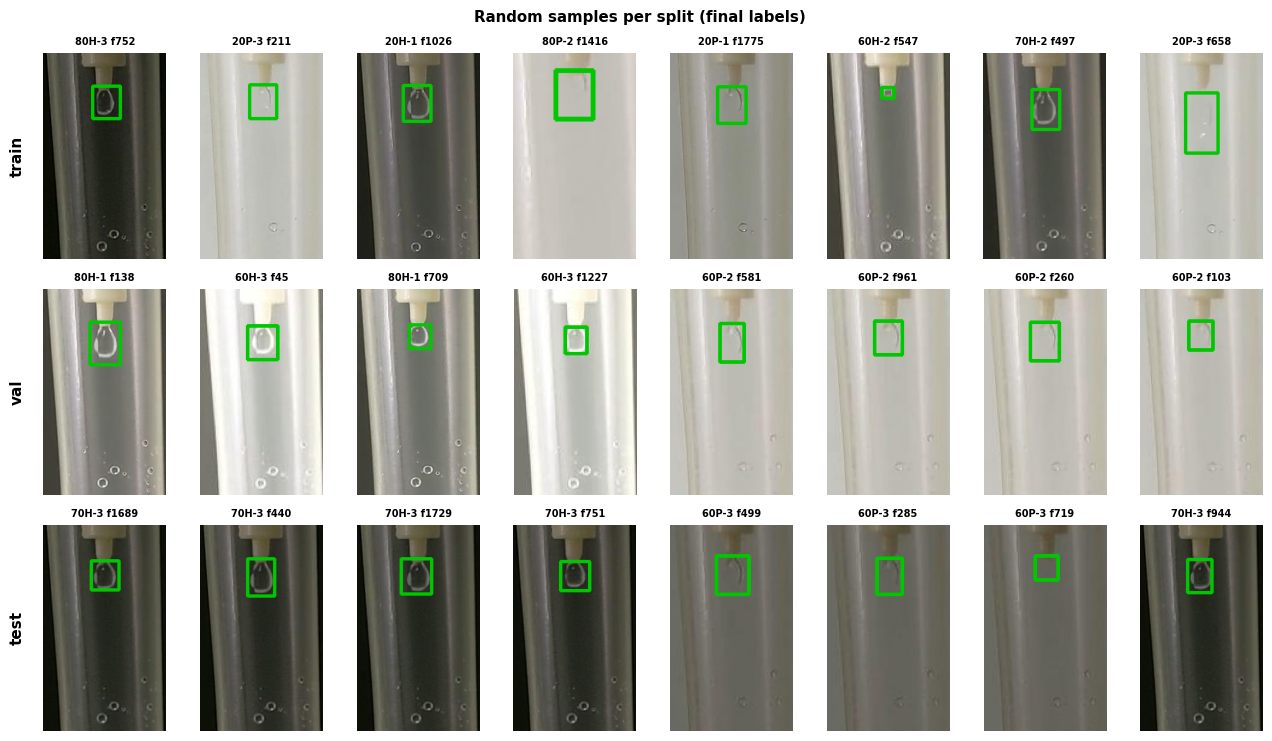

In [20]:
# random samples from every split, boxes read from the FINAL label files
fig, axes = plt.subplots(3, 8, figsize=(13, 7.5))
for row, sp in enumerate(["train", "val", "test"]):
    pool = sp_df[sp_df.split == sp]; pick = pool.sample(min(8, len(pool)), random_state=1)
    for a, (_, r) in zip(axes[row], pick.iterrows()):
        boxes, _ = read_boxes(r.label); r = r.copy(); r["boxes"] = boxes
        a.imshow(crop_at(r, half=0.08)); a.axis("off"); a.set_title(f"{short(r.video)} f{r.frame}", fontsize=7)
    axes[row][0].text(-0.15, 0.5, sp, transform=axes[row][0].transAxes, rotation=90, va="center", ha="right",
                      fontsize=11, fontweight="bold")
fig.suptitle("Random samples per split (final labels)", fontweight="bold"); plt.tight_layout(); plt.show()

**Insight:** every split contains both backgrounds and no video is shared. Not every rate can appear in val/test (2 test videos), which is acceptable for the **detector** (a drop looks the same at any rate). Rate accuracy is tested separately on complete videos.

### Labels before vs after cleaning

In [21]:
def label_stats(label_files):
    st = dict(images=0, boxes=0, empty=0, two_plus_boxes=0, polygons=0, broken_boxes=0, duplicates=0)
    for lab in label_files:
        boxes, kinds = read_boxes(lab)
        st["images"] += 1; st["boxes"] += len(boxes)
        st["empty"] += len(boxes) == 0; st["two_plus_boxes"] += len(boxes) > 1
        st["polygons"] += kinds.count("polygon")
        st["broken_boxes"] += any(b[2] < 0.004 or b[3] < 0.003 for b in boxes)
        st["duplicates"] += any(iou(boxes[i], boxes[j]) > 0.5 for i in range(len(boxes)) for j in range(i + 1, len(boxes)))
    return st

before = label_stats(glob.glob(f"{RAW}/**/labels/*.txt", recursive=True))
after = label_stats(glob.glob(f"{DS}/labels/*/*.txt"))
cmp = pd.DataFrame({"original (RAW)": before, "final (training set)": after})
cmp["change"] = cmp.iloc[:, 1] - cmp.iloc[:, 0]
cmp

,original (RAW),final (training set),change
images,9477,9468,-9
boxes,9414,9401,-13
empty,103,102,-1
two_plus_boxes,40,35,-5
polygons,7,0,-7
broken_boxes,7,0,-7
duplicates,3,0,-3


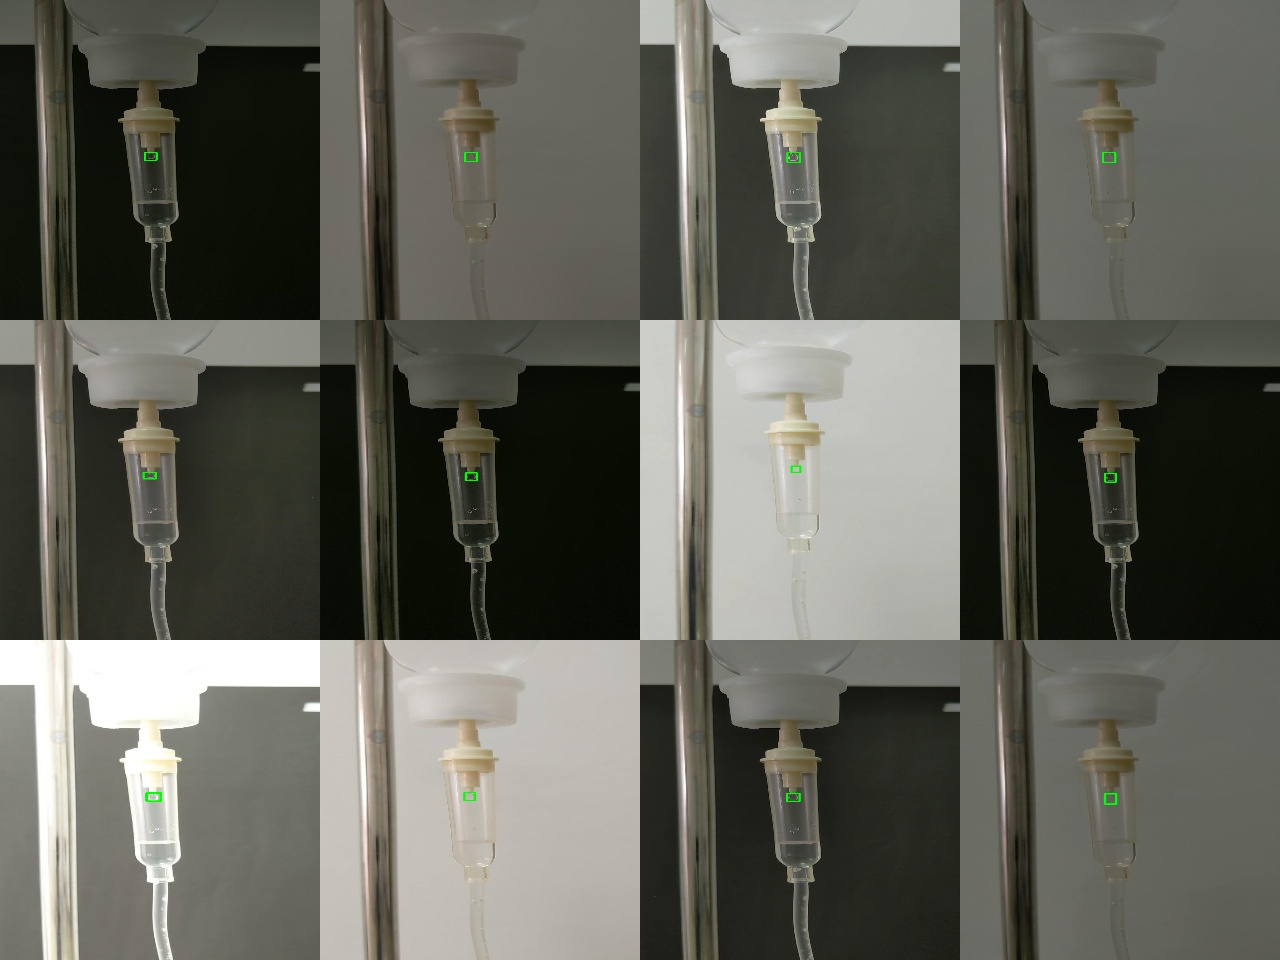

In [22]:
from IPython.display import Image as Show
Show(f"{DS}/check_boxes.jpg", width=900)

In [23]:
# save the finished dataset to Google Drive for the training notebook
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/iv_drip
!cd /content && zip -qr dataset.zip dataset && cp dataset.zip /content/drive/MyDrive/iv_drip/
print("saved: MyDrive/iv_drip/dataset.zip")

Mounted at /content/drive
saved: MyDrive/iv_drip/dataset.zip


## Summary: what this EDA changed in the plan
| Original plan | After EDA |
|---|---|
| Hegde dataset (3,458 images) | Not freely accessible → my fork of **Drip Infusion V2** (9,477 frames, 16 videos, 7 missed drops annotated) |
| Random 70/20/10 split | **Video level** split 11/3/2 with both backgrounds in each. Test never used for tuning |
| Count = track disappears after ≥ 3 frames & ≥ 10 px downward | **Hypothesis:** count tip drop cycles with a state machine and confirm on model predictions over complete videos |
| Default augmentation | Compare **default vs stronger translate/scale** (drop always at the same position), watch that drops stay visible |
| Validate rate on dataset videos | Only 18 to 44 % of frame indices present → **validate on complete external videos** (30 to 40 dpm) |
| Select model by mAP50 | Select by **recall** on val, then **counting accuracy** on videos. ROI crop or imgsz 960 as fallback |
| Clean labels in place | Clean on a **copy**, RAW kept, before and after table |